In [1]:
%matplotlib widget 

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
from pypulseq import Sequence
from tqdm import tqdm
from typing import Optional, Tuple
from Modules.Plan import KbNufft, KbNufftAdjoint
from Modules.FourierTransform import nonuniform_fourier_transform_forward, nonuniform_fourier_transform_adjoint
import Modules.ConcatSum 
from Modules.Regularizer import Regularizer
from Modules.CoilSens import cyclic_head_coil 
from Modules.Linops import LinearOperator, ChannelOperator, IdentityOperator
from Modules.NumSolvers import conjugate_gradient
import Modules.Resnet
import sys
sys.path.insert(0, "..")
from Modules import load_brain_phantom, default_system

torch.set_default_device("cuda:1")

/tmp/ipykernel_330275/2294680934.py:22: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf_inv, gz_inv, _ = pp.make_sinc_pulse(
/tmp/ipykernel_330275/2294680934.py:27: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


2-D TrueFISP timing check passed
  GRE block dur (TR) : 7.76 ms
  Readout train      : 5432 ms
  Scan time est       : 15.9 min


/opt/conda/lib/python3.13/site-packages/traitlets/traitlets.py:1396: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


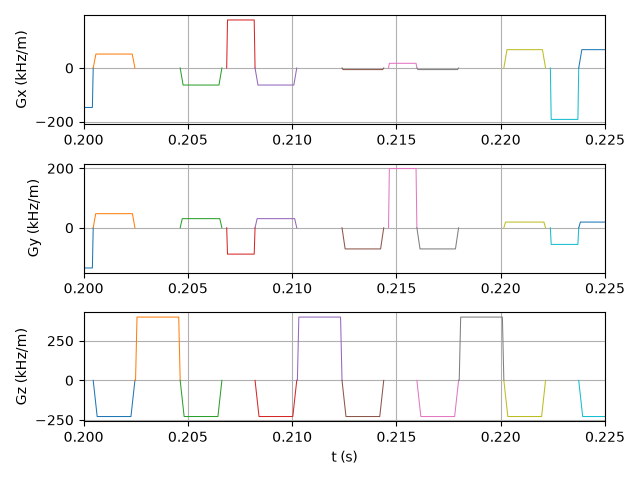

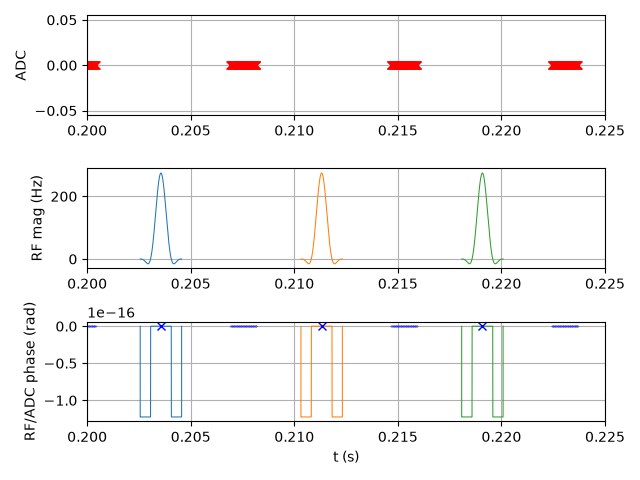

In [2]:
def truefisp_seq(
    fov: float = 250e-3,
    Nx: int = 64,
    alpha: float = 50.0,
    slice_thickness: float = 5e-3,
    TE: float = 3.98e-3,
    N_readout: int = 700,
    N_spokes: int = 128,
    R = 4,
    N_dummy: int = 20,
    TI_start: float = 20e-3,
    TI_inter: float = 0.0,     
    TD: float = 2000e-3,
    write_seq: bool = False,
    plot: bool = False,
) -> pp.Sequence:

    system = default_system()
    seq = pp.Sequence(system)
    deltak = 1 / fov

    rf_inv, gz_inv, _ = pp.make_sinc_pulse(
        flip_angle=np.pi, duration=10e-3, slice_thickness=slice_thickness,
        apodization=0.5, time_bw_product=4, system=system,
        return_gz=True, use='inversion')

    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5, duration=2e-3, flip_angle=alpha * np.pi / 180,
        slice_thickness=slice_thickness, system=system,
        time_bw_product=4, return_gz=True, use='excitation')

    gx_base = pp.make_trapezoid(channel='x', flat_area=Nx * deltak,
                                flat_time=6.4e-3 / 5, system=system)
    adc = pp.make_adc(num_samples=Nx, duration=gx_base.flat_time,
                      delay=gx_base.rise_time, system=system)

    gx_pre_base = pp.make_trapezoid(channel='x', area=-gx_base.area / 2,
                                    duration=2e-3, system=system)
    gz_reph     = pp.make_trapezoid(channel='z', area=-gz.area / 2,
                                    duration=2e-3, system=system)

    delay_TE = (
        np.ceil((
            TE
            - pp.calc_duration(gx_pre_base)
            - gz.fall_time - gz.flat_time / 2
            - pp.calc_duration(gx_base) / 2
        ) / seq.grad_raster_time) * seq.grad_raster_time
    )
    inv_duration   = pp.calc_duration(rf_inv, gz_inv)
    delay_TI_start = (
        np.ceil((TI_start - inv_duration / 2 - pp.calc_duration(gz) / 2)
                / seq.grad_raster_time) * seq.grad_raster_time
    )
    assert delay_TI_start > 0, 'TI_start too short'

    gre_block_dur = (
        pp.calc_duration(gx_pre_base)
        + pp.calc_duration(gz)          
        + delay_TE
        + pp.calc_duration(gx_base)     # readout
        + pp.calc_duration(gx_pre_base) # in-plane rewind
    )
    delay_TD = np.ceil(TD / seq.grad_raster_time) * seq.grad_raster_time
    delay_TI_inter = np.ceil(TI_inter / seq.grad_raster_time) * seq.grad_raster_time

    GA_DEG = 111.246
    #rf_phase = 0.0
    #rf_inc = 180.0          # FIX 4: alternate RF/ADC phase by 180 deg every TR
    spoke_counter = 0

    for seg in range(N_spokes // R):
        seq.add_block(rf_inv, gz_inv)
        seq.add_block(pp.make_delay(delay_TI_start))

        n_this_seg = N_readout + (N_dummy if seg == 0 else 0)
        for s in range(n_this_seg):
            is_dummy = (seg == 0) and (s < N_dummy)

            #rf.phase_offset  = rf_phase / 180 * np.pi
            #adc.phase_offset = rf_phase / 180 * np.pi
            #rf_inc   = rf_inc % 360
            #rf_phase = (rf_phase + rf_inc) % 360

            if is_dummy:
                angle = 0.0
            else:
                angle = np.deg2rad(spoke_counter * GA_DEG)
                spoke_counter += 1

            kx = np.cos(angle)
            ky = np.sin(angle)

            gx_pre = pp.make_trapezoid(channel='x', area=gx_pre_base.area * kx,
                                        duration=2e-3, system=system)
            gy_pre = pp.make_trapezoid(channel='y', area=gx_pre_base.area * ky,
                                        duration=2e-3, system=system)

            gx_rew = pp.make_trapezoid(channel='x', area=gx_pre_base.area * kx,   
                            duration=2e-3, system=system)
            gy_rew = pp.make_trapezoid(channel='y', area=gx_pre_base.area * ky,
                            duration=2e-3, system=system)

            #seq.add_block(gz_reph)
            seq.add_block(rf, gz)
            seq.add_block(gx_pre, gy_pre, gz_reph)
            seq.add_block(pp.make_delay(delay_TE))

            gx = pp.make_trapezoid(channel='x',
                                   amplitude=gx_base.amplitude * kx,
                                   flat_time=gx_base.flat_time,
                                   rise_time=gx_base.rise_time,
                                   fall_time=gx_base.fall_time,
                                   system=system)
            gy = pp.make_trapezoid(channel='y',
                                   amplitude=gx_base.amplitude * ky,
                                   flat_time=gx_base.flat_time,
                                   rise_time=gx_base.rise_time,
                                   fall_time=gx_base.fall_time,
                                   system=system)

            if is_dummy:
                seq.add_block(gx, gy)
            else:
                seq.add_block(gx, gy, adc)

            seq.add_block(gx_rew, gy_rew, gz_reph)

            if delay_TI_inter > 0 and s < n_this_seg - 1:
                seq.add_block(pp.make_delay(delay_TI_inter))

        seq.add_block(pp.make_delay(TD))

    ok, err = seq.check_timing()
    if ok:
        print('2-D TrueFISP timing check passed')
        print(f'  GRE block dur (TR) : {gre_block_dur * 1000:.2f} ms')
        print(f'  Readout train      : {N_readout * gre_block_dur * 1000:.0f} ms')
        est = N_spokes * (inv_duration + delay_TI_start
                          + N_readout * gre_block_dur + TD)
        print(f'  Scan time est       : {est / 60:.1f} min')
    else:
        print(f'Timing FAILED: {err}')

    seq.set_definition('FOV',  [fov, fov, slice_thickness])
    seq.set_definition('Name', 'us_trueFISP_2D_radial')
    if write_seq:
        seq.write('us_trueFISP_2D_Radial.seq')
    if plot:
        seq.plot(time_range=(0.2, 0.225))
    return seq, gre_block_dur, TI_start


seq, gre_block_dur, TI_start = truefisp_seq(write_seq=True, plot=False)

In [3]:
device = torch.device('cuda:1')
Nx = 64
phantom = mr0.util.load_phantom(size=(Nx, Nx))
n_channels = 8
fov = 250e-3

coil_sensitivities_recon = cyclic_head_coil((n_channels, Nx, Nx, 1)).to(torch.complex64)
coil_sensitivities_recon = coil_sensitivities_recon.flip((1, 2))
coil_sensitivities_recon = coil_sensitivities_recon[..., 0]

coil_sensitivities_sim = cyclic_head_coil(
    (n_channels, Nx, Nx, 1),
    fov_scaling=(phantom.size[0] / fov, phantom.size[1] / fov, 1),
).to(torch.complex64)
phantom.coil_sens = coil_sensitivities_sim.to(device)
phantom.B0 = 0 * phantom.B0
phantom.B1 = torch.ones(phantom.B1.shape, dtype=phantom.B1.dtype)

data = phantom.build()

In [4]:
N_readout = 500 #N_spokes = 128 // R 
Nx = 64
Nx_img, Ny_img = Nx, Nx        
fov = 250e-3; deltak = 1 / fov
mr0_seq = mr0.Sequence.import_file('us_trueFISP_2D_Radial.seq')
graph = mr0.compute_graph(mr0_seq, data, max_state_count=150, min_state_mag=1e-4)
signal = mr0.execute_graph(graph, mr0_seq, data, print_progress=True)
torch.save(signal.cpu(), 'us_trueFISP_signal.pt')

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 3.3406532 s
Compute Graph
Computing Graph: 31.23892 s
Analyze Graph
Analyzing Graph: 1.2492894 s
Converting Rust -> Python: 9.654007 s
<<<< Rust <<<<


Calculating repetitions:   0%|          | 0/22452 [00:00<?, ?it/s]

Done.


In [9]:
R = 4
N_spokes = 128 // R
N_readout = 700
Nx = 64
n_coils = 8
signal_all = signal.reshape(N_spokes, N_readout, Nx, n_coils)

def reconstruct_readouts_multicoil(
    signal_all, seq_file, readout_idx,
    N_readout, N_spokes, Nx_img, Ny_img, fov, device, n_coils):

    deltak = 1 / fov
    readout_idx = list(readout_idx)
    assert all(0 <= n < N_readout for n in readout_idx)

    mr_seq     = mr0.Sequence.import_file(seq_file)
    ktraj_full = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)
    ktraj_full = ktraj_full.reshape(-1, ktraj_full.shape[-1])[:, :2]

    sig_list, ktraj_list = [], []
    for seg in range(N_spokes):
        for n in readout_idx:
            start = (seg * N_readout + n) * Nx_img
            ktraj_list.append(ktraj_full[start : start + Nx_img])
            sig_list.append(signal_all[seg, n, :, :])   # (Nx, n_coils)

    sig   = torch.cat(sig_list, dim=0).to(torch.complex64)   # (n_samples, n_coils)
    ktraj = torch.cat(ktraj_list, dim=0)
    ktraj = ktraj / (deltak * Nx_img / 2) * np.pi * 0.85
    ktraj = ktraj.clamp(-np.pi, np.pi)
    ktraj = ktraj.T.contiguous().unsqueeze(0).to(device)

    r     = torch.linalg.norm(ktraj[0], dim=0)
    dcomp = r.view(1, 1, -1)
    r_max = r.max()
    dcomp = torch.clamp(r, min=0.01 * r_max).view(1, 1, -1)

    nufft_ob = tkbn.KbNufftAdjoint(
        im_size=(Nx_img, Ny_img), grid_size=(2 * Nx_img, 2 * Ny_img)
    ).to(device)

    # one adjoint NUFFT per coil, then root-sum-of-squares combine
    coil_images = []
    for c in range(n_coils):
        sig_c = sig[:, c].view(1, 1, -1).to(device)
        coil_images.append(nufft_ob(sig_c * dcomp, ktraj)[0, 0])

    combined = torch.sqrt(sum(im.abs()**2 for im in coil_images))
    return combined.cpu().numpy()


def ti_eff(readout_idx, TI_start, gre_block_dur, TI_inter=0.0):
    centre = np.mean(list(readout_idx))
    return TI_start + centre * (gre_block_dur + TI_inter)

In [11]:
device = torch.device('cuda:3')
Nx_img, Ny_img = Nx, Nx
fov = 250e-3; deltak = 1 / fov
readout_range = range(690, 693)   # the 10 readouts you want, each as its own image
n_channels = 8

images, ti_effs = [], []
for n in readout_range:
    img = reconstruct_readouts_multicoil(
        signal_all, 'us_trueFISP_2D_Radial.seq', [n],   # single readout -> single image
        N_readout=N_readout, N_spokes=N_spokes,
        Nx_img=Nx_img, Ny_img=Ny_img, fov=fov, device=device, n_coils = n_coils)
    ti_ms = ti_eff([n], TI_start, gre_block_dur) * 1000
    images.append(np.rot90(img, k=1 ))
    ti_effs.append(ti_ms)
    print(f'Readout {n:2d}  TI_eff={ti_ms:.0f} ms')

print(f'Done — {len(images)} images, TI_eff {ti_effs[0]:.0f} -> {ti_effs[-1]:.0f} ms')

RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


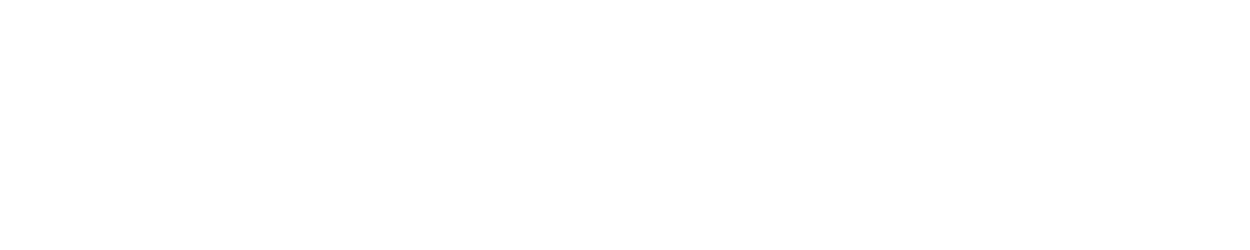

In [7]:
n_imgs = len(images)
ncols = min(5, n_imgs)
nrows = int(np.ceil(n_imgs / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.5, nrows * 2.5))
for i, ax in enumerate(np.atleast_1d(axes).ravel()):
    if i < n_imgs:
        ax.imshow(images[i], cmap='gray')
        ax.set_title(f'RO {readout_range.start + i}\nTI={ti_effs[i]:.0f}ms', fontsize=9)
    ax.axis('off')
plt.suptitle(f'TrueFISP — {n_imgs} readout-resolved images', fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
class DeepADMM(nn.Module):

    def __init__(self, shape, rho_init=0.1, maxiter_admm=10, maxiter_cg=5):

        super().__init__()
        self.rho = nn.Parameter(torch.tensor(rho_init, dtype=torch.float32))
        self.regularizer = Regularizer(shape)
        self.I = IdentityOperator(shape)
        self.maxiter_admm = maxiter_admm
        self.maxiter_cg = maxiter_cg

    def forward(self,Q,b,x, disable_progressbar=True):
        z = torch.zeros(self.I.shape[0], dtype=x.dtype)
        u = torch.zeros(self.I.shape[0], dtype=x.dtype)

        for iteration in range(self.maxiter_admm):
    
            x = conjugate_gradient(
                Q + self.rho * self.I,
                b=b + self.rho * (z - u),
                x=x,
                maxiter=self.maxiter_cg,
                disable_progressbar=True,
            )
    
            z = self.regularizer(x + u)
            u = u + x - z
    
        return x

In [8]:
N_spokes = 128 // 4
class NonuniformFourierTransformOperator(LinearOperator):

    def __init__(
        self,
        k: torch.Tensor,
        input_shape: Tuple[int, ...],
        device: Optional[torch.device] = None,
    ):
        nD, nK = k.shape
        nC, nX, nY = input_shape

        self.n_modes = (nX, nY)
        self.k = k
        self.forward_shape = (nC, nX, nY, 1)
        self.adjoint_shape = (nC, nK)
        self.shape = (
            int(2 * torch.prod(torch.tensor(self.adjoint_shape))),
            int(2 * torch.prod(torch.tensor(self.forward_shape))),
        )
        self.nufft_ob = KbNufft(im_size=self.n_modes).to(device)
        self.adj_ob = KbNufftAdjoint(im_size=self.n_modes).to(device)

        self.dtype = torch.float32
        self.device = device

    def _matvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.forward_shape)
        y = nonuniform_fourier_transform_forward(self.k, x, nufft_ob=self.nufft_ob)
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

    def _rmatvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.adjoint_shape)
        y = nonuniform_fourier_transform_adjoint(
            self.k, x, self.n_modes, adj_ob=self.adj_ob
        )
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

seq = pp.Sequence()
seq.read("us_trueFISP_2D_Radial.seq")
kspace = seq.calculate_kspace()
k_traj_adc = kspace[0]
k_traj_adc = k_traj_adc[:2, :]
k_traj_radius = np.sqrt(np.sum(k_traj_adc**2, axis=0, keepdims=True))
k_traj_adc = k_traj_adc / k_traj_radius.max() * 0.5
k_traj_adc = torch.tensor(k_traj_adc, dtype=torch.float32)

readout_indices = list(range(690, 695))
mask_train = torch.zeros((N_spokes, N_readout, Nx), dtype=torch.bool)
mask_train[:, readout_indices, :] = True
mask_train = mask_train.reshape(-1)
k_traj_train = k_traj_adc[:, mask_train]
data_train = signal.clone().reshape((-1, n_channels)).permute((1, 0))[:, mask_train].contiguous()

#F_sub = NonuniformFourierTransformOperator(k_traj_sub, (n_channels, Nx, Nx))
#C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))
#A_sub = F_sub @ C
#data_sub_flat = data_sub.view(torch.float32).ravel()

RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


Training on Readouts 25-29: 100%|██████████| 25/25 [03:07<00:00,  7.48s/it, loss=0.1301]


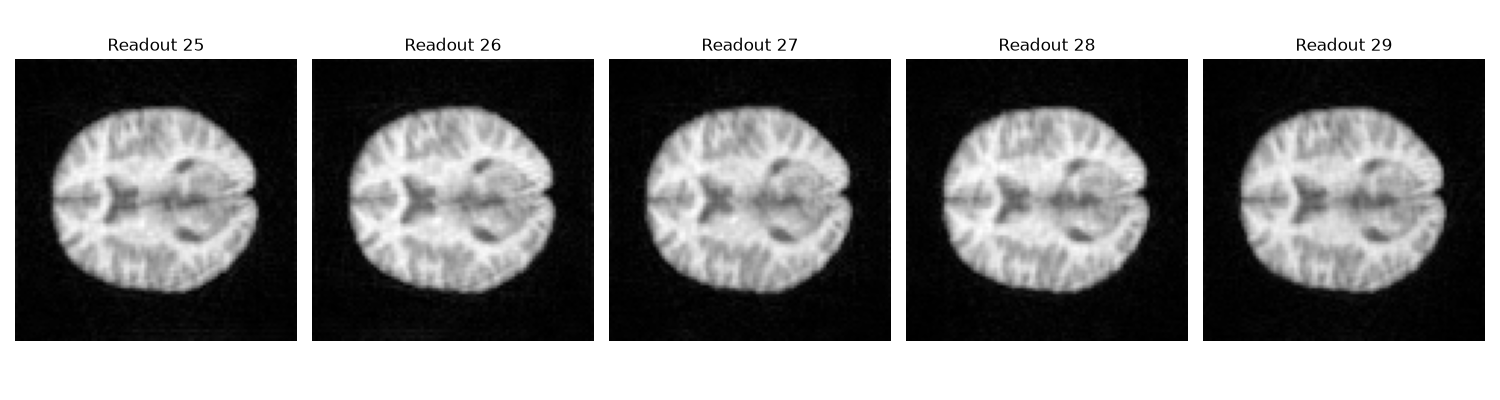

In [28]:
device = torch.device('cuda:1')
shape = (Nx, Nx, 1)
torch.manual_seed(0)
model = DeepADMM(shape, rho_init=0.1, maxiter_admm=10, maxiter_cg=5)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

nK_train = k_traj_train.shape[1]
num_splits = 25

model.train()
losses = []
progress_bar = tqdm(range(num_splits), desc="Training on Readouts 25-29")

for split in progress_bar:
    np.random.seed(split)

    indices = np.arange(nK_train)
    np.random.shuffle(indices)
    index_src, index_tar = np.split(indices, 2)

    k_traj_src = k_traj_train[:, index_src]
    k_data_src = data_train[:, index_src].view(torch.float32).ravel()

    k_traj_tar = k_traj_train[:, index_tar]
    k_data_tar = data_train[:, index_tar].view(torch.float32).ravel()

    F_src = NonuniformFourierTransformOperator(k_traj_src, (n_channels, Nx, Nx))
    F_tar = NonuniformFourierTransformOperator(k_traj_tar, (n_channels, Nx, Nx))
    C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))

    Q_src = C.H @ F_src.H @ F_src @ C
    b_src = C.H @ F_src.H @ k_data_src
    
    x_out = model(Q_src, b_src, b_src, disable_progressbar=True)
    k_data_pred = F_tar @ C @ x_out

    loss = torch.linalg.norm(k_data_pred - k_data_tar, ord=1) / torch.linalg.norm(
        k_data_tar, ord=1
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    progress_bar.set_postfix(loss=f"{loss.item():.4f}")

model.eval()
reconstructed_images = []

for r_idx in readout_indices:

    mask_single = torch.zeros((N_spokes, N_readout, Nx), dtype=torch.bool)
    mask_single[:, r_idx, :] = True
    mask_single = mask_single.reshape(-1)

    k_traj_single = k_traj_adc[:, mask_single]
    data_single = signal.clone().reshape((-1, n_channels)).permute((1, 0))[:, mask_single].contiguous()
    data_single_flat = data_single.view(torch.float32).ravel()

    F_single = NonuniformFourierTransformOperator(k_traj_single, (n_channels, Nx, Nx))
    A_single = F_single @ C
    
    Q_single = A_single.H @ A_single
    b_single = A_single.H @ data_single_flat

    with torch.no_grad():
        x_recon = model(Q_single, b_single, b_single, disable_progressbar=True)

    img_complex = x_recon.view(torch.complex64).reshape((Nx, Nx))
    reconstructed_images.append(img_complex.cpu().numpy())

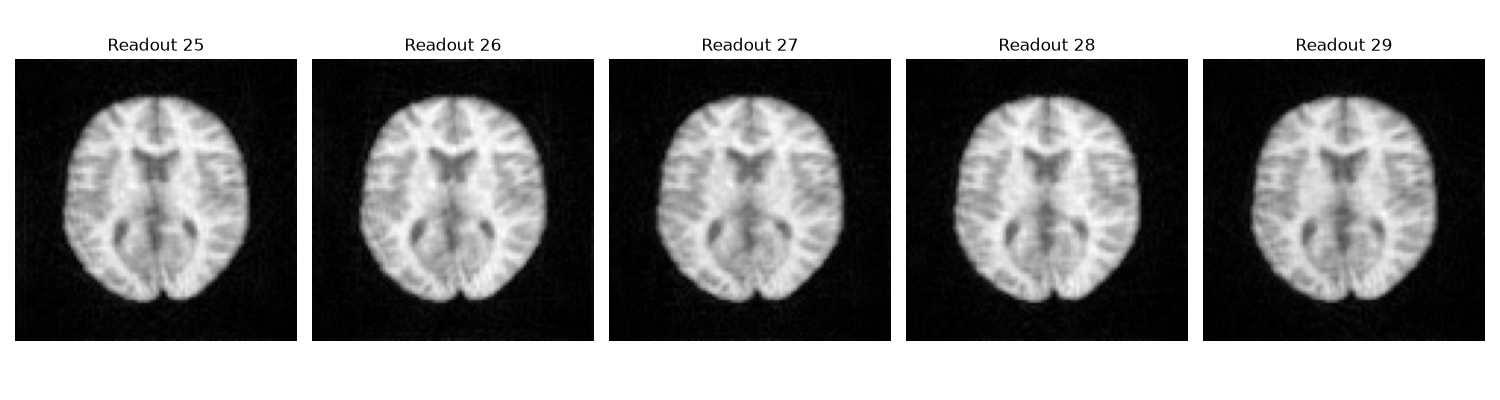

In [30]:
fig, axes = plt.subplots(1, len(readout_indices), figsize=(15, 4))

for i, r_idx in enumerate(readout_indices):
    img_magnitude = np.abs(reconstructed_images[i])
    img_rotated = np.rot90(img_magnitude, k=-1)
    axes[i].imshow(img_rotated, cmap='gray')
    axes[i].set_title(f"Readout {r_idx}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [10]:
data = signal.clone()
data = data.reshape((-1, n_channels)).permute((1, 0))
data = data.contiguous()
AHd_sub = A_sub.H @ data_sub.view(torch.float32).ravel()
AHd_image = AHd_sub.view(torch.complex64).reshape((Nx, Nx))
Q = A.H @ A
b = AHd
x = torch.zeros(Nx * Nx, dtype=torch.complex64).view(torch.float32)
x_recon = conjugate_gradient(Q, b, x, maxiter=30)
x_recon_image = x_recon.view(torch.complex64).reshape((Nx, Nx))

  0%|          | 0/30 [00:00<?, ?it/s]

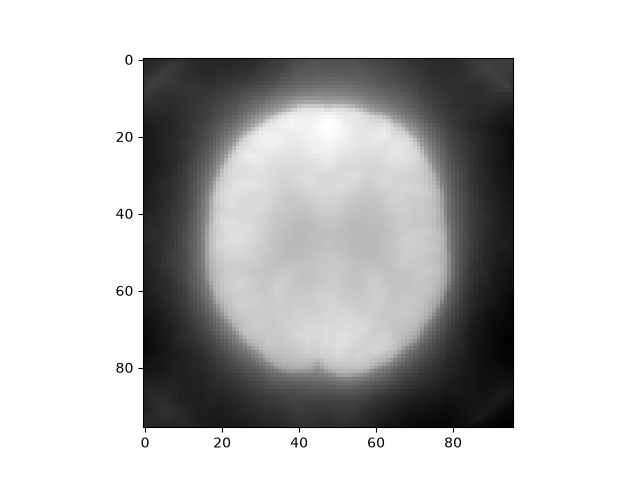

In [16]:
plt.figure()
plt.imshow(torch.abs(AHd_image).cpu().numpy().T, cmap="gray")
plt.show()

In [12]:
Nx = 96
torch.manual_seed(0)
shape = (Nx, Nx, 1)
model_init = DeepADMM(shape, rho_init=0.1, maxiter_admm=10, maxiter_cg=5)

with torch.no_grad():
    x_deep_admm_init = model_init(Q, b, b)
x_deep_admm_init_image = x_deep_admm_init.view(torch.complex64).reshape((Nx, Nx))

In [13]:
shape = (Nx, Nx, 1)

torch.manual_seed(0)
model = DeepADMM(
    shape,
    rho_init=0.1,
    maxiter_admm=10,
    maxiter_cg=5,
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

nK = k_traj_adc.shape[1]
num_splits = 25

model.train()
losses = []

progress_bar = tqdm(range(num_splits), desc="Self-supervised splits")

for split in progress_bar:

    np.random.seed(split)

    indices = np.arange(nK)
    np.random.shuffle(indices)
    index_src, index_tar = np.split(indices, 2)

    k_traj_src = k_traj_adc[:, index_src]
    k_data_src = data[:, index_src].view(torch.float32).ravel()

    k_traj_tar = k_traj_adc[:, index_tar]
    k_data_tar = data[:, index_tar].view(torch.float32).ravel()

    F_src = NonuniformFourierTransformOperator(k_traj_src, (n_channels, Nx, Nx))
    F_tar = NonuniformFourierTransformOperator(k_traj_tar, (n_channels, Nx, Nx))
    C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))

    Q_src = C.H @ F_src.H @ F_src @ C
    b_src = C.H @ F_src.H @ k_data_src

    x_out = model(Q_src, b_src, b_src, disable_progressbar=True)

    k_data_pred = F_tar @ C @ x_out

    loss = torch.linalg.norm(k_data_pred - k_data_tar, ord=1) / torch.linalg.norm(
        k_data_tar, ord=1
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    progress_bar.set_postfix(loss=f"{loss.item():.4f}")

Self-supervised splits: 100%|██████████| 25/25 [03:18<00:00,  7.96s/it, loss=1.0534]


In [14]:
model.eval()
F_full = NonuniformFourierTransformOperator(k_traj_adc, (n_channels, Nx, Nx))
C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))
x0 = torch.zeros(Nx * Nx, dtype=torch.complex64).view(torch.float32)
with torch.no_grad():
    x_deep_admm_trained = model(Q, b, b)

x_deep_admm_trained_image = x_deep_admm_trained.view(torch.complex64).reshape(
    (Nx, Nx)
)

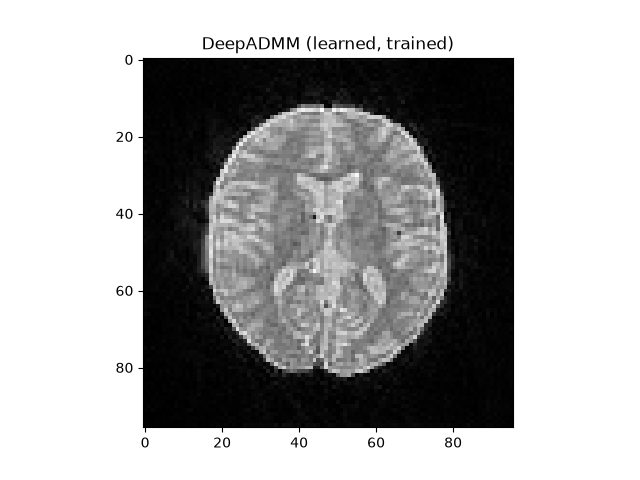

In [15]:
plt.imshow(torch.abs(x_deep_admm_trained_image).cpu().numpy().T, cmap="gray")
plt.title("DeepADMM (learned, trained)")
plt.show()